In [2]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import numpy as np
import pandas as pd
import h5py
import pickle
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import colors
from matplotlib.gridspec import GridSpec
from scipy.optimize import minimize
from scipy.sparse import csr_matrix
from joblib import Parallel, delayed
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *


# Panel d -- resting-state ROI-to-ROI correlation, raw vs CLS-disentangled (mouse C1 = cm229)

In [4]:
mouse = 'cm229'  # C1

CLS_root = str(PREPARES / "CLS") + "/"
spatial = load_pickle(CLS_root + 'M2S1M1_NNLS_spatial_' + mouse)
W_S1M2M1 = spatial['W_S1M2M1']
TCs_matrix = spatial['TCs_matrix']
mask = spatial['mask']
index_M2s = spatial['index_M2s']
all_bdps = spatial['all_bdps_w_order']
num_bdps = len(all_bdps)
mask_reshape = mask.reshape((256 * 256))
print('W_S1M2M1', W_S1M2M1.shape, 'TCs_matrix', TCs_matrix.shape, 'num_bdps', num_bdps)


W_S1M2M1 (44219, 42) TCs_matrix (42, 6120) num_bdps 40


In [5]:

T_PRE_REST, T_STOP_REST = 160, 220
figure6_legacy_root = str(FIGURES / "figure6-legacy") + "/"
with h5py.File(figure6_legacy_root + 'final_' + mouse + '_MM_jrgeco_' + mouse, 'r') as hf:
    MM_jrgeco_REST_slice = hf['MM_jrgeco_REST'][:, :, T_PRE_REST:T_STOP_REST, :]

figure_config_root = str(PREPARES / "config") + "/"
with h5py.File(figure_config_root + 'mask_midline_v2_' + mouse + '.mat', 'r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

ss = MM_jrgeco_REST_slice.shape
concat_jrgeco_full_rest = MM_jrgeco_REST_slice.transpose((0, 1, 3, 2)).reshape((256, 256, ss[2] * ss[3]))
concat_jrgeco_full_rest = np.multiply(concat_jrgeco_full_rest,
    np.repeat(mask_midline[:, :, np.newaxis], repeats=concat_jrgeco_full_rest.shape[-1], axis=2))
MM_jrgeco_reshape = concat_jrgeco_full_rest.reshape((256 * 256, -1))
print('MM_jrgeco_reshape', MM_jrgeco_reshape.shape, '-- must match TCs_matrix columns:', TCs_matrix.shape[1])
assert MM_jrgeco_reshape.shape[1] == TCs_matrix.shape[1]


MM_jrgeco_reshape (65536, 6120) -- must match TCs_matrix columns: 6120


In [6]:
total_T = TCs_matrix.shape[1]
to_cut = total_T % 4
if to_cut != 0:
    TCs_matrix = TCs_matrix[:, :-to_cut]
    MM_jrgeco_reshape = MM_jrgeco_reshape[:, :-to_cut]
    total_T -= to_cut
split_size = total_T // 4
dict_ind = {fold_k: np.arange(split_size * fold_k, split_size * (fold_k + 1)) for fold_k in range(4)}
print('total_T', total_T, 'split_size', split_size)


total_T 6120 split_size 1530


In [7]:
def nnls_optimization_with_constraints(A, b, x_init, constraints):
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual) ** 2

    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    result = minimize(objective, x_init, method='SLSQP', constraints=constraints,
                       jac=objective_jac, options={'disp': False})
    return result.x


def return_constraints(H_ROI, median_here, index_M2s, k):
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({'type': 'eq', 'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])})
    constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k * median_here})
    return constraints


In [8]:
# raw (k=0) correlation maps, 4 continuous folds -- top row of panel d
dict_corrmaps_raw_4folds = {}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    X = MM_jrgeco_reshape[mask_reshape == 1, :][:, ind_here]
    H_ROI = TCs_matrix[:, ind_here]
    median_M2_tc = np.median(H_ROI[index_M2s, :], 0)
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, X[:, i_t], H_ROI[:, i_t],
        return_constraints(H_ROI[:, i_t], median_M2_tc[i_t], index_M2s, 0))
        for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    H_fitted = H_fitted[:, ~np.isnan(H_fitted[0, :])].copy()
    corr_map = np.corrcoef(H_fitted[:num_bdps, :], H_fitted[:num_bdps, :])[:num_bdps, num_bdps:]
    dict_corrmaps_raw_4folds[i_fold] = corr_map
    print('fold', i_fold, 'raw done')


fold 0 raw done
fold 1 raw done
fold 2 raw done
fold 3 raw done


In [9]:
# disentangled (k=0.50) correlation maps, 4 continuous folds -- bottom row of panel d
optimal_k = 0.5
dict_corrmaps_optimized_4folds = {}
for i_fold in range(4):
    ind_here = dict_ind[i_fold]
    X = MM_jrgeco_reshape[mask_reshape == 1, :][:, ind_here]
    H_ROI = TCs_matrix[:, ind_here]
    median_M2_tc = np.median(H_ROI[index_M2s, :], 0)
    temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
        W_S1M2M1, X[:, i_t], H_ROI[:, i_t],
        return_constraints(H_ROI[:, i_t], median_M2_tc[i_t], index_M2s, optimal_k))
        for i_t in range(X.shape[1]))
    H_fitted = np.vstack(temp).T
    H_fitted = H_fitted[:, ~np.isnan(H_fitted[0, :])].copy()
    corr_map = np.corrcoef(H_fitted[:num_bdps, :], H_fitted[:num_bdps, :])[:num_bdps, num_bdps:]
    dict_corrmaps_optimized_4folds[i_fold] = corr_map
    print('fold', i_fold, 'optimized (k=0.5) done')


fold 0 optimized (k=0.5) done
fold 1 optimized (k=0.5) done
fold 2 optimized (k=0.5) done
fold 3 optimized (k=0.5) done


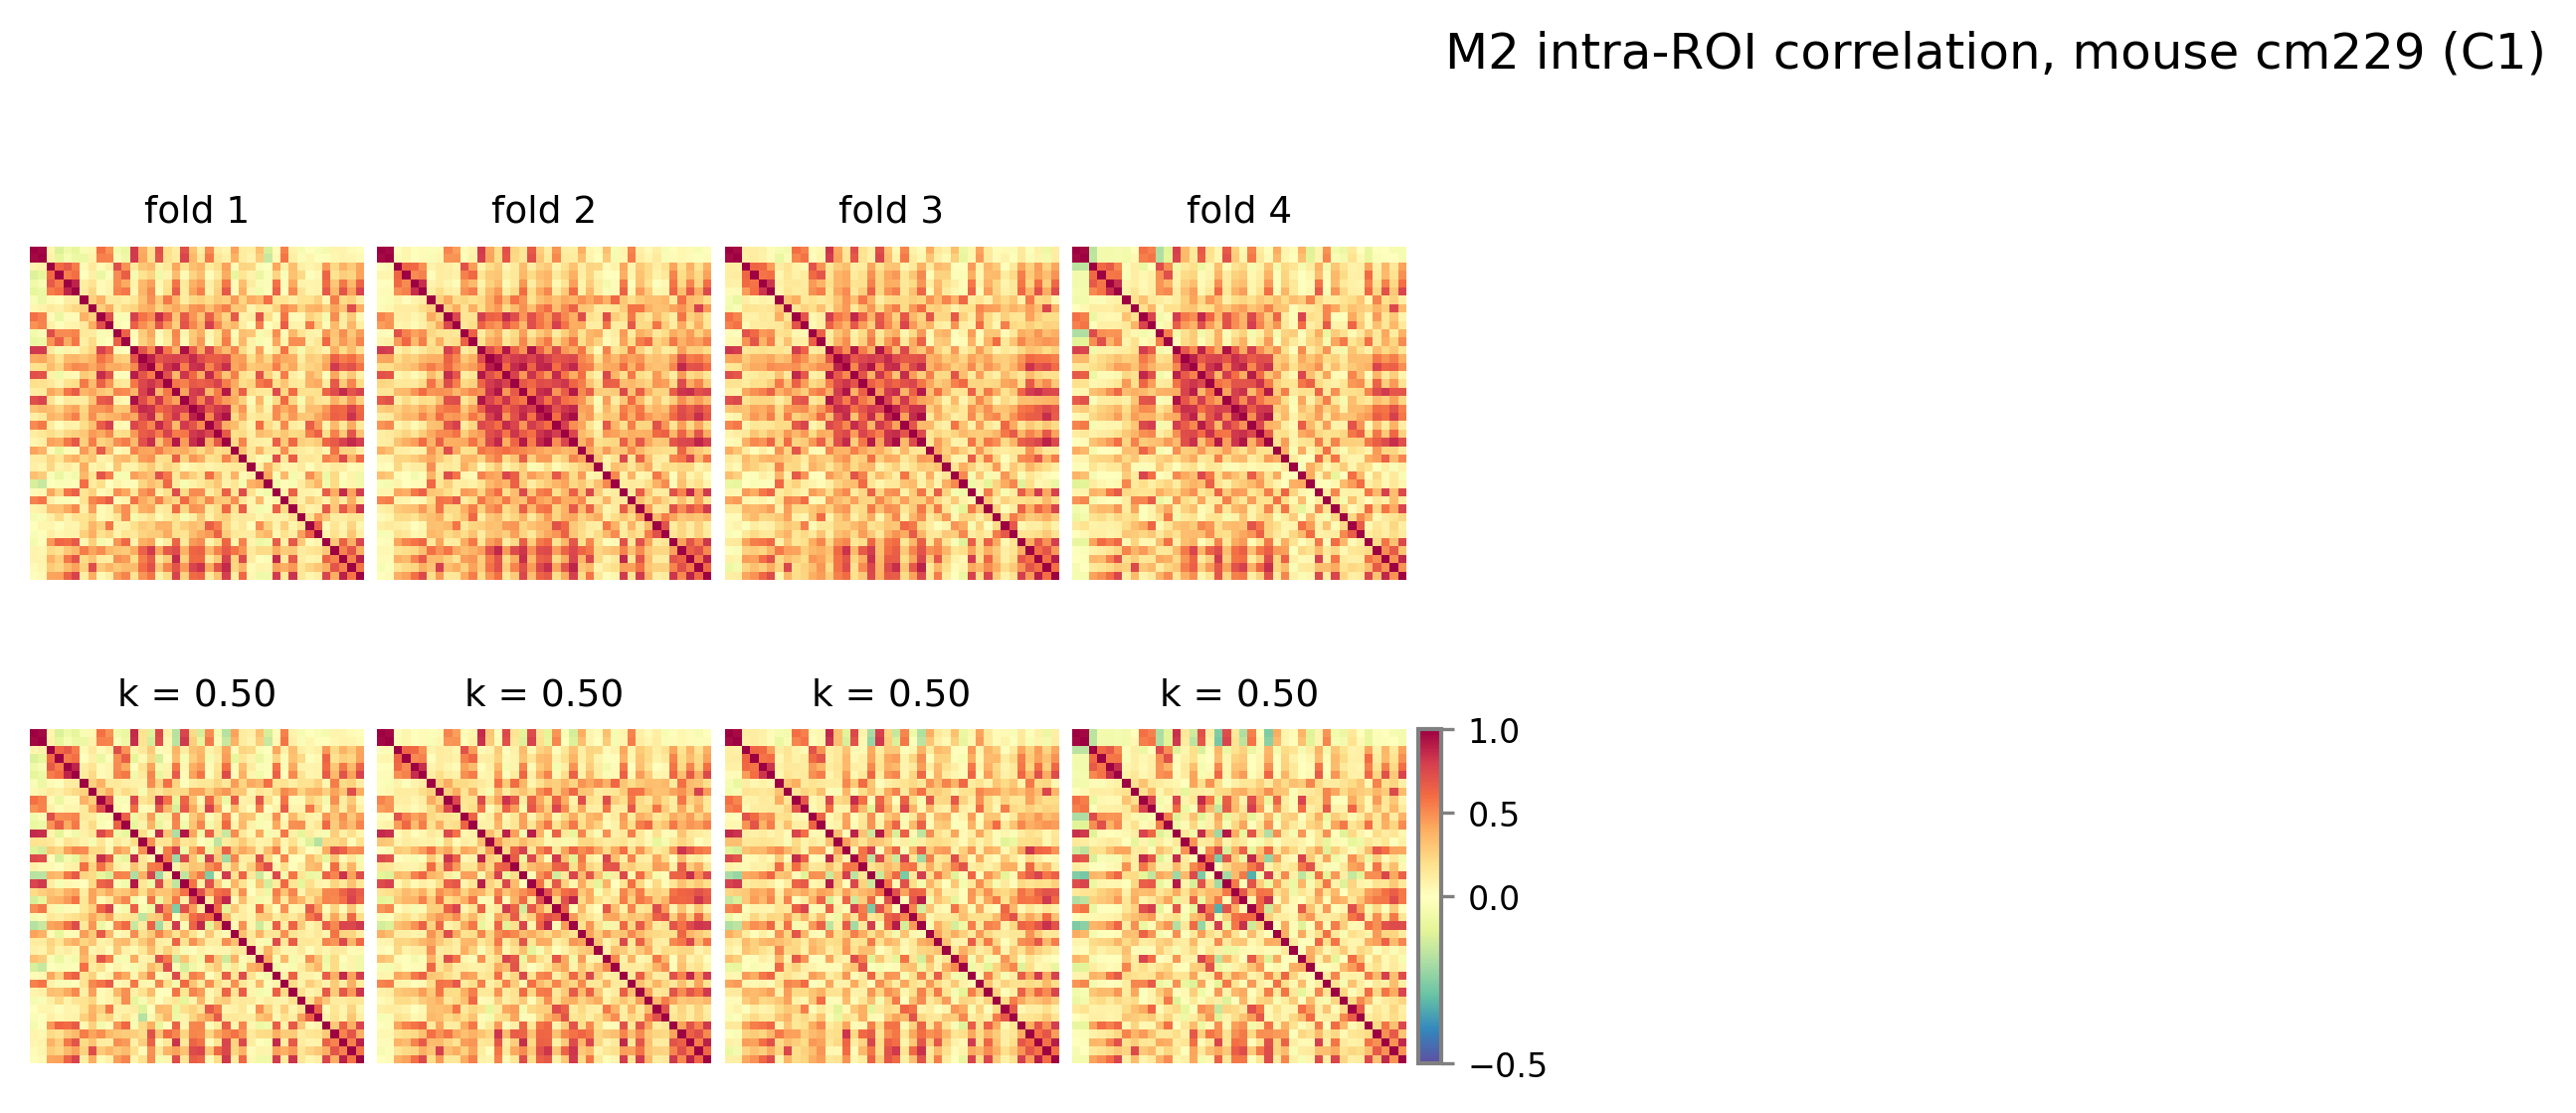

In [10]:
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
gs = GridSpec(100, 100)
fig = plt.figure(figsize=(30, 30), dpi=300)

divnorm = colors.TwoSlopeNorm(vmin=-0.5, vcenter=0., vmax=1)
y_offset = 20; x_offset = 20
y_start = y_offset; y_stop = y_start + 5
x_start = x_offset; x_stop = x_start + 5
axes_raw = []
for i_fold in range(4):
    ax = fig.add_subplot(gs[y_start:y_stop, x_start:x_stop])
    ax.imshow(dict_corrmaps_raw_4folds[i_fold], cmap='Spectral_r', norm=divnorm)
    ax.set_title(f'fold {i_fold + 1}', fontsize=9)
    ax.axis('off')
    axes_raw.append(ax)
    x_start = x_stop; x_stop = x_start + 5

y_start = y_offset + 7; y_stop = y_start + 5
x_start = x_offset; x_stop = x_start + 5
for i_fold in range(4):
    ax = fig.add_subplot(gs[y_start:y_stop, x_start:x_stop])
    sbp = ax.imshow(dict_corrmaps_optimized_4folds[i_fold], cmap='Spectral_r', norm=divnorm)
    ax.set_title(f'k = {optimal_k:0.2f}', fontsize=9)
    ax.axis('off')
    x_start = x_stop; x_stop = x_start + 5

ax99 = fig.add_subplot(gs[y_start:y_stop, x_start:x_stop - 4])
cb = fig.colorbar(sbp, ticks=[-0.5, 0, 0.5, 1], cax=ax99, orientation='vertical')
cb.ax.tick_params(labelsize=8, length=3, color='gray')
cb.outline.set_edgecolor('gray'); cb.outline.set_linewidth(1)
ax99.set_aspect(15); ax99.set_anchor('W')

axes_raw[0].set_ylabel('raw (k=0)', fontsize=9)
plt.suptitle(f'M2 intra-ROI correlation, mouse {mouse} (C1)', y=0.75)
plt.savefig('figS9d-corr-maps-raw-vs-optimized_cm229.svg', format='svg', dpi=300)


# Panel e -- selecting the optimal disentanglement parameter k (mice C1-C3)

In [11]:
CLS_root = str(PREPARES / "CLS") + "/"
MOUSE_LABEL = {'cm229': 'C1', 'cm128': 'C2', 'cm126': 'C3'}

rows = []
for m in MOUSE_LABEL:
    d = load_pickle(CLS_root + 'dict_results_corr_' + m)
    ks = d['ks']
    for i_fold in range(4):
        for k, score in zip(ks, d['dict_score_corr'][i_fold]):
            rows.append({'mouse': MOUSE_LABEL[m], 'fold': i_fold + 1, 'k': k,
                         'intra-M2 correlation score': score})
df_k_sweep = pd.DataFrame(rows)
print(df_k_sweep.shape)
df_k_sweep.groupby('mouse').size()


(180, 4)


mouse
C1    60
C2    60
C3    60
dtype: int64

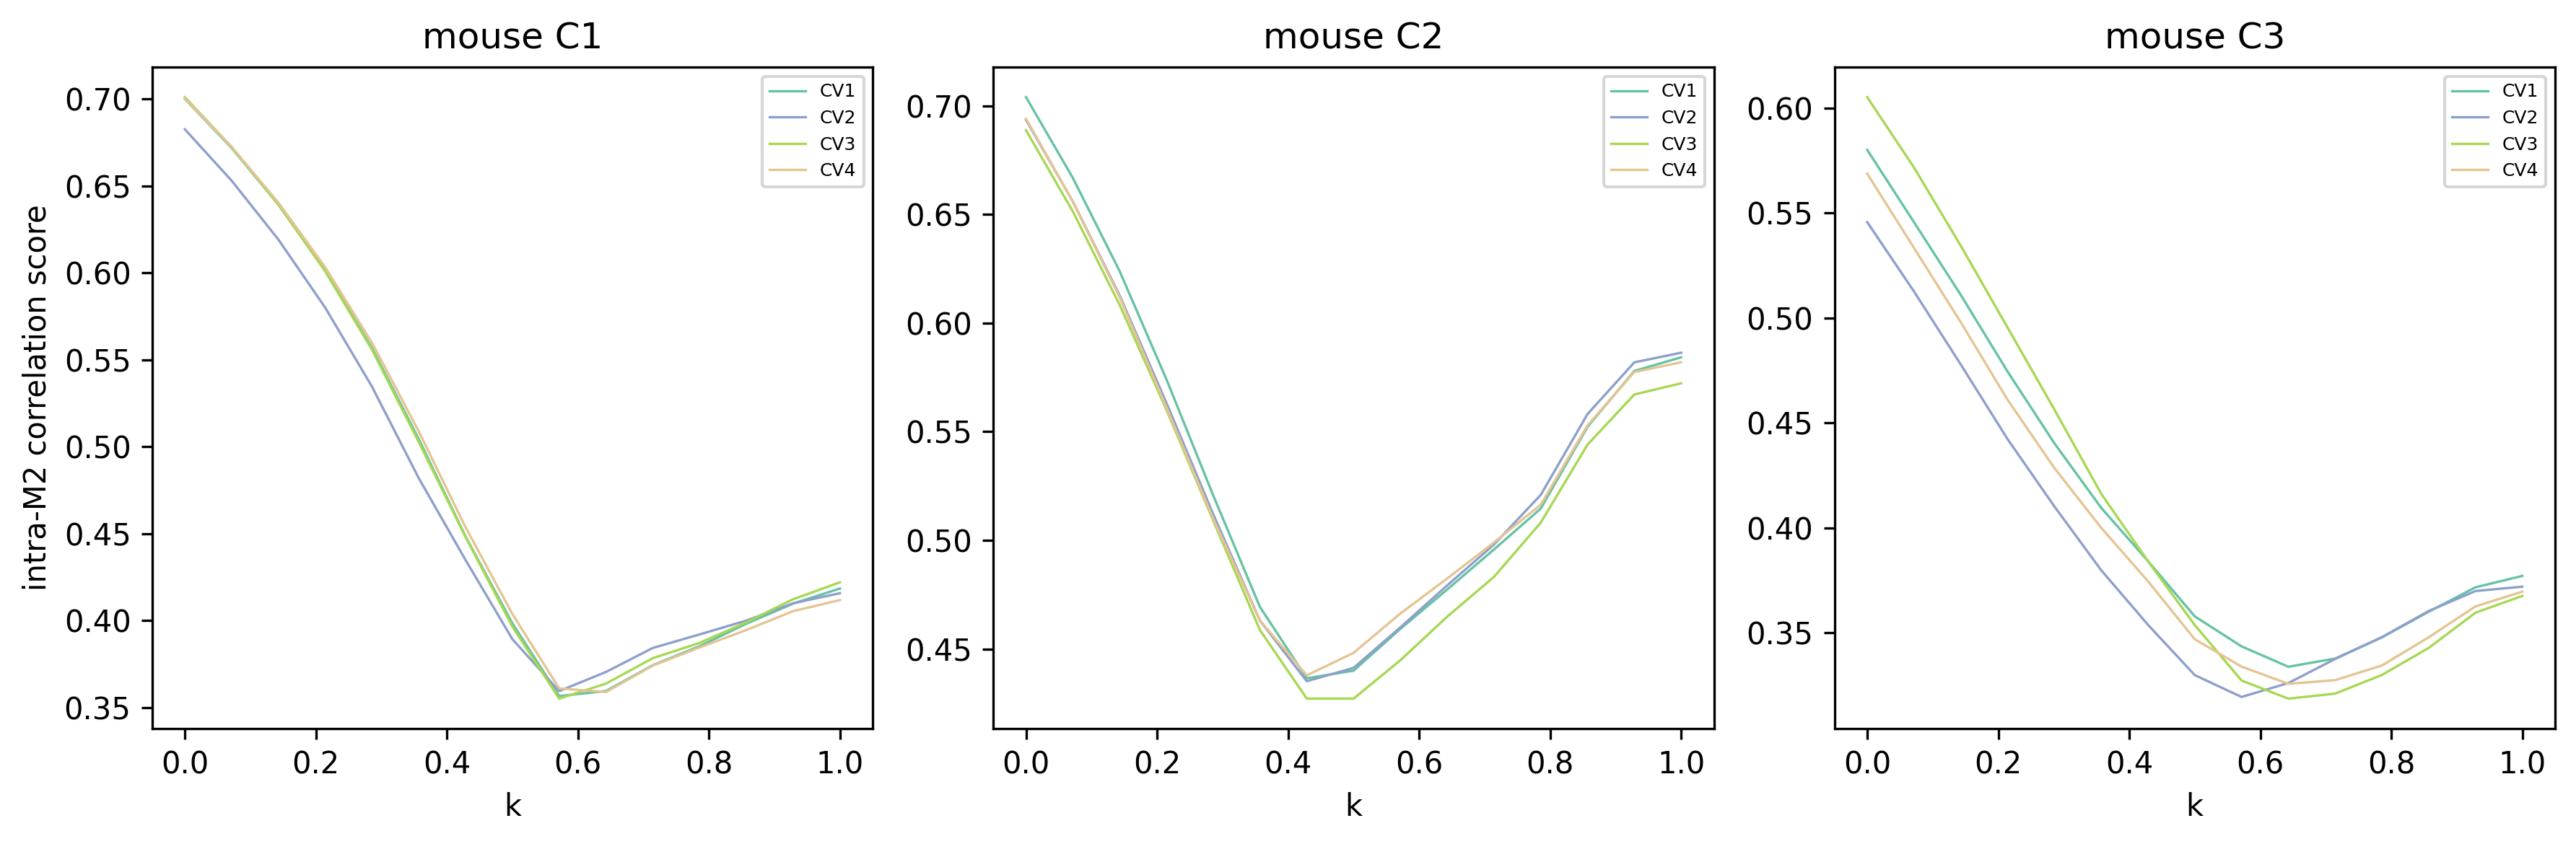

In [12]:
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=300)
temp_colors = plt.get_cmap('Set2').colors
for ax, m in zip(axes, ['C1', 'C2', 'C3']):
    sub = df_k_sweep[df_k_sweep.mouse == m]
    for i_fold in range(1, 5):
        f = sub[sub.fold == i_fold]
        ax.plot(f['k'], f['intra-M2 correlation score'], color=temp_colors[(i_fold - 1) * 2 % len(temp_colors)],
                label=f'CV{i_fold}', linewidth=0.8)
    ax.set_title(f'mouse {m}')
    ax.set_xlabel('k')
    if m == 'C1':
        ax.set_ylabel('intra-M2 correlation score')
    ax.legend(fontsize=6)
plt.tight_layout()
plt.savefig('figS9e-corr-score-vs-k.svg', format='svg', dpi=300)
